## 1. Carregando as ferramentas

In [78]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils import shuffle
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Análise de dados

In [79]:
data = pd.read_csv('Churn.csv')

In [80]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           9091 non-null   float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), str(3)
memory usage: 1.1 MB


In [81]:
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2.0,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1.0,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8.0,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1.0,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2.0,125510.82,1,1,1,79084.10,0


In [82]:
print(data['Surname'].nunique())
print(data['Geography'].nunique())
# Verificando a quantidade de valores únicos nas colunas Surname e Geography.

2932
3


In [83]:
data.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,9091.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,4.997690,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.894723,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,2.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [84]:
print(data['Tenure'].isnull().sum())
#Verificando a quantidade de linhas com valores ausentes na coluna Tenure

909


In [85]:
data_corr = data.drop(['Surname', 'Geography', 'Gender'], axis=1).corr()
print(data_corr)
#Verificando a correlação entre as colunas

                 RowNumber  CustomerId  CreditScore       Age    Tenure  \
RowNumber         1.000000    0.004202     0.005840  0.000783 -0.007322   
CustomerId        0.004202    1.000000     0.005308  0.009497 -0.021418   
CreditScore       0.005840    0.005308     1.000000 -0.003965 -0.000062   
Age               0.000783    0.009497    -0.003965  1.000000 -0.013134   
Tenure           -0.007322   -0.021418    -0.000062 -0.013134  1.000000   
Balance          -0.009067   -0.012419     0.006268  0.028308 -0.007911   
NumOfProducts     0.007246    0.016972     0.012238 -0.030680  0.011979   
HasCrCard         0.000599   -0.014025    -0.005458 -0.011721  0.027232   
IsActiveMember    0.012044    0.001665     0.025651  0.085472 -0.032178   
EstimatedSalary  -0.005988    0.015271    -0.001384 -0.007201  0.010520   
Exited           -0.016571   -0.006248    -0.027094  0.285323 -0.016761   

                  Balance  NumOfProducts  HasCrCard  IsActiveMember  \
RowNumber       -0.009067   

In [86]:
print(data['Exited'].value_counts(normalize=True)*100)
# Verificando o equilibrio das classes target

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64



Fazendo uma análise inicial no DF, cheguei a algumas conclusões:

1º Irei excluir a coluna Surname, chequei que ela possui 2932 valores únicos e ao aplicar o OHE iria aumentar considerávelmente as colunas do DF e por se tratar de uma coluna de identificação de clientes não tem relevância no fato dele cancelar a conta ou não.

2º As váriaveis categóricas onde aplicarei o OHE são a Geography e o Gender, pois eles podem ter dados interessantes para o modelo e não possuem uma grande variedade de valores únicos.

3º Assim como a coluna Surname, as colunas RowNumber e CustomerId são colunas de identificação, o que também não tem necessidade de estar no modelo, pois elas podem gerar algum tipo de ruído, portanto irei excluí-las.

4º Irei aplicar o Scaler nas colunas CreditScore, Age, Tenure, Balance, NumOfProducts e EstimatedSalary pois elas podem ter dados interessantes para o modelo porém as escalas delas são muito distintas.

5º As colunas HasCrCard e IsActiveMember apesar de serem dados numéricos, eles representam valores booleanos, ou seja, são categóricos, portanto não irei aplicar o scaler neles.

6º A coluna Tenure possuia 909 valores ausentes, o que corresponde aproximadamente 9% dos dados do DF, analisei a correlação entre ela e o Exited e possui uma correlação muito baixa (-0.016761), porém ela ainda pode ser útil se usarmos um modelo não linear, portanto verifiquei no describe que ela possui uma distribuição simétrica, pelo fato da média e a mediana serem muito próximas (4,99 e 5), portanto irei completar após a divisão dos conjuntos os valores ausentes com a mediana para analisarmos como será o impacto no nosso modelo

7º Notei o desbalanceamento nas classes na coluna Exited (0 = 79,63% e 1 = 20,37%), vamos usar alguns métodos para tentar melhorar isso, a princípio usarei o class_weight para verificar qual será o resultado, se não for satisfatório partiremos para o oversampling e undersampling


## 3. Feature Engineering

In [87]:
data = data.drop(['RowNumber','CustomerId','Surname'], axis=1)
#Removendo colunas que não são necessárias no modelo

In [88]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  str    
 2   Gender           10000 non-null  str    
 3   Age              10000 non-null  int64  
 4   Tenure           9091 non-null   float64
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(3), int64(6), str(2)
memory usage: 859.5 KB


In [89]:
x = data.drop('Exited', axis=1)
y = data['Exited']
#Separando features de target

In [90]:
x_temp, x_test, y_temp, y_test = train_test_split(x,y, test_size=0.2, stratify=y, random_state=12345)
#Separando o conjunto de teste do conjunto temporário

In [91]:
x_train, x_valid, y_train, y_valid = train_test_split(x_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=12345)
#A partir do conjunto temporário criei os conjuntos de treino e validação

In [92]:
print(f"O comprimento do data frame original é: {len(x)}")
print(f"O comprimento do conjunto temporário é: {len(x_temp)}")
print(f"O comprimento do conjunto de teste é: {len(x_test)}")
print(f"O comprimento do conjunto de validação é: {len(x_valid)}")
print(f"O comprimento do conjunto de treinamento é: {len(x_train)}")
# Verificando o tamanho dos conjuntos

O comprimento do data frame original é: 10000
O comprimento do conjunto temporário é: 8000
O comprimento do conjunto de teste é: 2000
O comprimento do conjunto de validação é: 2000
O comprimento do conjunto de treinamento é: 6000


In [93]:
x_train.loc[:,'Tenure'] = x_train.loc[:,'Tenure'].fillna(x_train.loc[:,'Tenure'].median())
x_valid.loc[:,'Tenure'] = x_valid.loc[:,'Tenure'].fillna(x_train.loc[:,'Tenure'].median())
x_test.loc[:,'Tenure'] = x_test.loc[:,'Tenure'].fillna(x_train.loc[:,'Tenure'].median())


Efetuei acima a substituição dos valores em branco da coluna Tenure em cada conjunto do data frame pela mediana do conjunto de treinamento, com o objetivo de evitar vazamentos de dados.

In [94]:
cat_cols = ['Geography', 'Gender']
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
#Separando as colunas categóricas e numéricas para executar os métodos OHE e scaler 

In [95]:
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ], remainder='passthrough'
                               )

# Criei processo no qual ao posso adicionar ao pipeline e ele aplicará o scaler nas colunas numéricas e o OHE nas colunas categóricas
# No OHE usei handle_unknown='ignore' para ele não gerar falha caso alguma nova categoria seja adicionada futuramente

## 4. Modelo Regressão Logistica Desbalanceado

In [96]:
pipeline_rl_desbalanceado = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(solver='liblinear'))
])
pipeline_rl_desbalanceado.fit(x_train, y_train)
# Criei um pipeline onde primeiro ele executa o pré processamento das colunas numéricas e categóricas e em seguida executa a regressão logística

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['CreditScore','Geography','Gender',...,'HasCrCard','IsActiveMember', 'EstimatedSalary']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

In [97]:
x_pred = pipeline_rl_desbalanceado.predict(x_valid)
print(classification_report(y_valid, x_pred))
print(f1_score(y_valid, x_pred))
#Verificando F1 


              precision    recall  f1-score   support

           0       0.83      0.97      0.90      1593
           1       0.67      0.21      0.32       407

    accuracy                           0.82      2000
   macro avg       0.75      0.59      0.61      2000
weighted avg       0.80      0.82      0.78      2000

0.32149532710280376


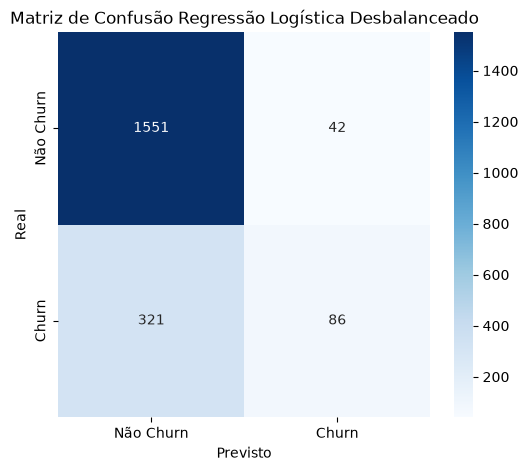

In [98]:
x_pred = pipeline_rl_desbalanceado.predict(x_valid)
cm = confusion_matrix(y_valid, x_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Não Churn', 'Churn'],
            yticklabels=['Não Churn', 'Churn'])
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title('Matriz de Confusão Regressão Logística Desbalanceado')
plt.show()
#Plotando a matriz de confusão

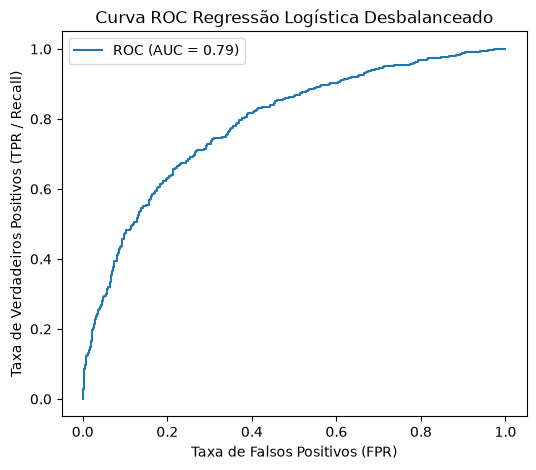

0.787541007879991


In [99]:
x_proba = pipeline_rl_desbalanceado.predict_proba(x_valid)[:, 1]

fpr, tpr, thresholds_roc = roc_curve(y_valid, x_proba)
auc_score = roc_auc_score(y_valid, x_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ROC (AUC = {auc_score:.2f})')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR / Recall)')
plt.title('Curva ROC Regressão Logística Desbalanceado')
plt.legend()
plt.show()

print(auc_score)
#Traçando a curva AUC-ROC

In [100]:
probabilities_valid = pipeline_rl_desbalanceado.predict_proba(x_valid)
probabilities_one_valid = probabilities_valid[:,1]
# Encontrando as probabilidades da classe 1

In [101]:
print(probabilities_one_valid[:5])

[0.48357855 0.52897737 0.1673942  0.12645897 0.21969779]


In [102]:
for threshold in np.arange(0, 0.4, 0.02):
    predicted_valid = probabilities_one_valid > threshold 
    precision = precision_score(y_valid, predicted_valid)
    recall = recall_score(y_valid, predicted_valid)
    f1 = f1_score(y_valid, predicted_valid)
    print(
        'Limiar = {:.2f} | Precisão = {:.3f}, Sensibilidade = {:.3f}, F1_score = {:.3f}'.format(
            threshold, precision, recall, f1
        )
    )
# Percorrendo os valores limiares para encontrar o melhor F1

Limiar = 0.00 | Precisão = 0.203, Sensibilidade = 1.000, F1_score = 0.338
Limiar = 0.02 | Precisão = 0.204, Sensibilidade = 1.000, F1_score = 0.339
Limiar = 0.04 | Precisão = 0.213, Sensibilidade = 0.993, F1_score = 0.351
Limiar = 0.06 | Precisão = 0.230, Sensibilidade = 0.975, F1_score = 0.372
Limiar = 0.08 | Precisão = 0.251, Sensibilidade = 0.951, F1_score = 0.397
Limiar = 0.10 | Precisão = 0.267, Sensibilidade = 0.919, F1_score = 0.413
Limiar = 0.12 | Precisão = 0.288, Sensibilidade = 0.897, F1_score = 0.436
Limiar = 0.14 | Precisão = 0.311, Sensibilidade = 0.860, F1_score = 0.457
Limiar = 0.16 | Precisão = 0.334, Sensibilidade = 0.833, F1_score = 0.477
Limiar = 0.18 | Precisão = 0.357, Sensibilidade = 0.781, F1_score = 0.490
Limiar = 0.20 | Precisão = 0.383, Sensibilidade = 0.742, F1_score = 0.505
Limiar = 0.22 | Precisão = 0.405, Sensibilidade = 0.690, F1_score = 0.511
Limiar = 0.24 | Precisão = 0.434, Sensibilidade = 0.661, F1_score = 0.524
Limiar = 0.26 | Precisão = 0.453, Sens

Ao executar o modelo com as classes desbalanceadas verificamos que a precisão deu um valor de 0.67, porém o recall foi um valor horrível, somente 0.21, o que demonstra que dos clientes que realmente cancelaram, o nosso modelo conseguiu prever somente aproximadamente 21%, com isso o valor do nosso F1 também é bem baixo (0.32), isso de deve muito por conta do desbalanceamento das classes, onde não temos muitos dados de clientes que fizeram o cancelamento para treinar o modelo.

Já a curva AUC-ROC aprensentou até que um valor positivo, ficando em 0.79

## 5. Regressão Logística - Class Weight = Balanced

In [103]:
pipeline_rl = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', solver='liblinear'))
])
pipeline_rl.fit(x_train, y_train)


# Criei um pipeline onde primeiro ele executa o pré processamento das colunas numéricas e categóricas e em seguida executa a regressão logística com o hiperparâmetro class_weight='balanced'
# A idéia é ele dar mais peso para classe minotirária "1" para balancear as classes.

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['CreditScore','Geography','Gender',...,'HasCrCard','IsActiveMember', 'EstimatedSalary']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

In [104]:
x_pred = pipeline_rl.predict(x_valid)
print(classification_report(y_valid, x_pred))
print(f1_score(y_valid, x_pred))
#Verificando F1 


              precision    recall  f1-score   support

           0       0.91      0.72      0.80      1593
           1       0.40      0.72      0.51       407

    accuracy                           0.72      2000
   macro avg       0.65      0.72      0.66      2000
weighted avg       0.81      0.72      0.74      2000

0.5113043478260869


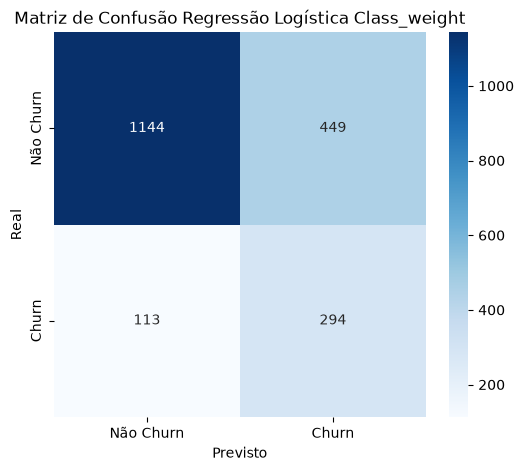

In [105]:
x_pred = pipeline_rl.predict(x_valid)
cm = confusion_matrix(y_valid, x_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Não Churn', 'Churn'],
            yticklabels=['Não Churn', 'Churn'])
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title('Matriz de Confusão Regressão Logística Class_weight')
plt.show()
#Plotando a matriz de confusão

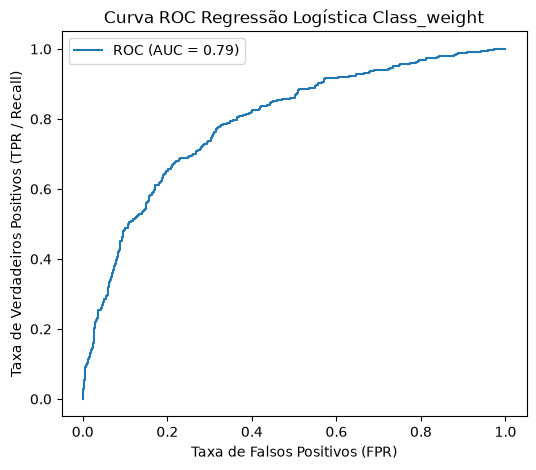

0.7918149274081479


In [106]:
x_proba = pipeline_rl.predict_proba(x_valid)[:, 1]

fpr, tpr, thresholds_roc = roc_curve(y_valid, x_proba)
auc_score = roc_auc_score(y_valid, x_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ROC (AUC = {auc_score:.2f})')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR / Recall)')
plt.title('Curva ROC Regressão Logística Class_weight')
plt.legend()
plt.show()

print(auc_score)
#Traçando a curva AUC-ROC

In [107]:
probabilities_valid = pipeline_rl.predict_proba(x_valid)
probabilities_one_valid = probabilities_valid[:,1]
# Encontrando as probabilidades da classe 1

In [108]:
print(probabilities_one_valid[:5])

[0.78085621 0.80742912 0.41795919 0.33882223 0.55912935]


In [109]:
for threshold in np.arange(0, 0.4, 0.02):
    predicted_valid = probabilities_one_valid > threshold 
    precision = precision_score(y_valid, predicted_valid)
    recall = recall_score(y_valid, predicted_valid)
    f1 = f1_score(y_valid, predicted_valid)
    print(
        'Limiar = {:.2f} | Precisão = {:.3f}, Sensibilidade = {:.3f}, F1_score = {:.3f}'.format(
            threshold, precision, recall, f1
        )
    )
# Percorrendo os valores limiares para encontrar o melhor F1

Limiar = 0.00 | Precisão = 0.203, Sensibilidade = 1.000, F1_score = 0.338
Limiar = 0.02 | Precisão = 0.203, Sensibilidade = 1.000, F1_score = 0.338
Limiar = 0.04 | Precisão = 0.203, Sensibilidade = 1.000, F1_score = 0.338
Limiar = 0.06 | Precisão = 0.204, Sensibilidade = 1.000, F1_score = 0.339
Limiar = 0.08 | Precisão = 0.204, Sensibilidade = 1.000, F1_score = 0.339
Limiar = 0.10 | Precisão = 0.207, Sensibilidade = 1.000, F1_score = 0.343
Limiar = 0.12 | Precisão = 0.209, Sensibilidade = 0.998, F1_score = 0.346
Limiar = 0.14 | Precisão = 0.213, Sensibilidade = 0.993, F1_score = 0.350
Limiar = 0.16 | Precisão = 0.217, Sensibilidade = 0.990, F1_score = 0.357
Limiar = 0.18 | Precisão = 0.223, Sensibilidade = 0.980, F1_score = 0.364
Limiar = 0.20 | Precisão = 0.229, Sensibilidade = 0.978, F1_score = 0.372
Limiar = 0.22 | Precisão = 0.235, Sensibilidade = 0.968, F1_score = 0.378
Limiar = 0.24 | Precisão = 0.242, Sensibilidade = 0.956, F1_score = 0.386
Limiar = 0.26 | Precisão = 0.250, Sens

## 6. Regressão Logística - Upsampling

In [110]:
def upsample(features, target, repeat):
    features_zeros = features[target == 0]
    features_ones = features[target == 1]
    target_zeros = target[target == 0]
    target_ones = target[target == 1]

    features_upsampled = pd.concat([features_zeros] + [features_ones] * repeat)
    target_upsampled = pd.concat([target_zeros] + [target_ones] * repeat)

    features_upsampled, target_upsampled = shuffle(
        features_upsampled, target_upsampled, random_state=12345
    )
    return features_upsampled, target_upsampled

# Construindo a função para realizaro upsampling na classe 1

In [111]:
x_train_upsampled, y_train_upsampled = upsample(x_train, y_train, repeat=3)

pipeline_upsampled = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(solver = 'liblinear', random_state=12345))
])

pipeline_upsampled.fit(x_train_upsampled, y_train_upsampled)

# Chamando a função e criando um pipeline para executar o modelo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['CreditScore','Geography','Gender',...,'HasCrCard','IsActiveMember', 'EstimatedSalary']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

In [112]:
x_pred = pipeline_upsampled.predict(x_valid)
print(classification_report(y_valid, x_pred))
print(f1_score(y_valid, x_pred))
#Verificando F1 

              precision    recall  f1-score   support

           0       0.90      0.80      0.85      1593
           1       0.45      0.65      0.53       407

    accuracy                           0.77      2000
   macro avg       0.68      0.72      0.69      2000
weighted avg       0.81      0.77      0.78      2000

0.5344129554655871


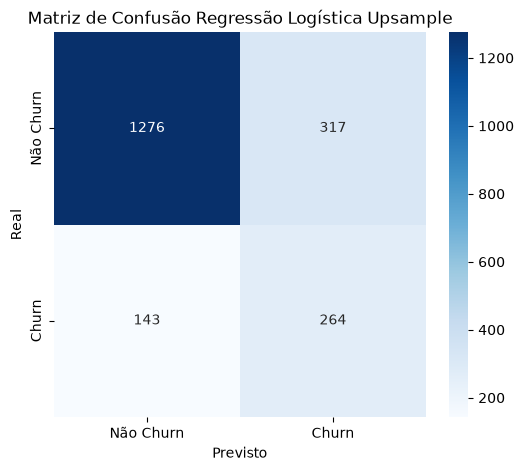

In [113]:
x_pred = pipeline_upsampled.predict(x_valid)
cm = confusion_matrix(y_valid, x_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Não Churn', 'Churn'],
            yticklabels=['Não Churn', 'Churn'])
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title('Matriz de Confusão Regressão Logística Upsample')
plt.show()
#Plotando a matriz de confusão

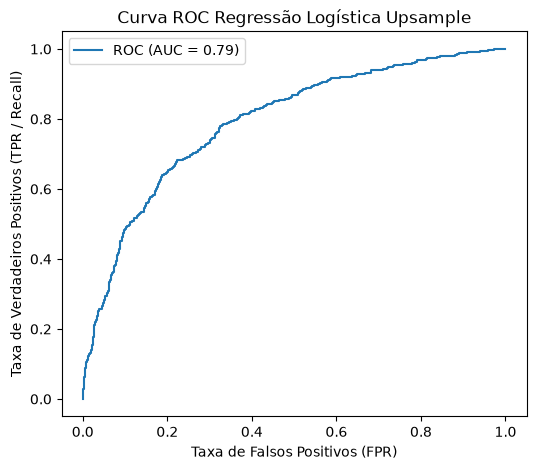

0.7912380793736726


In [114]:
x_proba = pipeline_upsampled.predict_proba(x_valid)[:, 1]

fpr, tpr, thresholds_roc = roc_curve(y_valid, x_proba)
auc_score = roc_auc_score(y_valid, x_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ROC (AUC = {auc_score:.2f})')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR / Recall)')
plt.title('Curva ROC Regressão Logística Upsample')
plt.legend()
plt.show()

print(auc_score)
#Traçando a curva AUC-ROC

In [115]:
probabilities_valid = pipeline_upsampled.predict_proba(x_valid)
probabilities_one_valid = probabilities_valid[:,1]
# Encontrando as probabilidades da classe 1

In [116]:
print(probabilities_one_valid[:5])

[0.73352401 0.7642822  0.35973234 0.28640056 0.48577937]


In [117]:
for threshold in np.arange(0, 0.4, 0.02):
    predicted_valid = probabilities_one_valid > threshold 
    precision = precision_score(y_valid, predicted_valid)
    recall = recall_score(y_valid, predicted_valid)
    f1 = f1_score(y_valid, predicted_valid)
    print(
        'Limiar = {:.2f} | Precisão = {:.3f}, Sensibilidade = {:.3f}, F1_score = {:.3f}'.format(
            threshold, precision, recall, f1
        )
    )
# Percorrendo os valores limiares para encontrar o melhor F1

Limiar = 0.00 | Precisão = 0.203, Sensibilidade = 1.000, F1_score = 0.338
Limiar = 0.02 | Precisão = 0.203, Sensibilidade = 1.000, F1_score = 0.338
Limiar = 0.04 | Precisão = 0.203, Sensibilidade = 1.000, F1_score = 0.338
Limiar = 0.06 | Precisão = 0.204, Sensibilidade = 1.000, F1_score = 0.339
Limiar = 0.08 | Precisão = 0.207, Sensibilidade = 1.000, F1_score = 0.343
Limiar = 0.10 | Precisão = 0.210, Sensibilidade = 0.995, F1_score = 0.347
Limiar = 0.12 | Precisão = 0.215, Sensibilidade = 0.990, F1_score = 0.353
Limiar = 0.14 | Precisão = 0.222, Sensibilidade = 0.983, F1_score = 0.362
Limiar = 0.16 | Precisão = 0.229, Sensibilidade = 0.978, F1_score = 0.371
Limiar = 0.18 | Precisão = 0.236, Sensibilidade = 0.968, F1_score = 0.379
Limiar = 0.20 | Precisão = 0.244, Sensibilidade = 0.953, F1_score = 0.389
Limiar = 0.22 | Precisão = 0.254, Sensibilidade = 0.941, F1_score = 0.400
Limiar = 0.24 | Precisão = 0.263, Sensibilidade = 0.929, F1_score = 0.410
Limiar = 0.26 | Precisão = 0.274, Sens

Analisando os valores, podemos verificar que a precisão apresentou uma melhora no modelo upsampling em relação ao class_weight (0.45 x 0.4) porém apresenta uma leve queda no recall o que resultado no F1 de 0.53, um pouco abaixo ainda do que é solicitado pelo projeto, a curva AUC-ROC permanece praticamente a mesma, marcando 0.79, pois essa métrica avalia o modelo em todos os limiares e não somente em um único limiar, como não conseguimos alcançar o F1 necessário, iremos partir para os testes nos modelos random forest.

## 7. Random Forest - Class Weight = Balanced

In [118]:
pipeline_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        class_weight='balanced',
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=5,
        random_state=12345
    ))
])

pipeline_rf.fit(x_train, y_train)
# Criação de um pipeline para executar o pré processamento nas colunas numéricas e categóricas e executar o modelo Random Forest
# Estou verificando a quantidade de árvores, a profundeza de cada árvore e o número mínimo de amostras que uma folha precisa ter

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['CreditScore','Geography','Gender',...,'HasCrCard','IsActiveMember', 'EstimatedSalary']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

In [119]:
x_pred = pipeline_rf.predict(x_valid)
print(classification_report(y_valid, x_pred))
print(f1_score(y_valid, x_pred))
#Verificando F1 

              precision    recall  f1-score   support

           0       0.93      0.86      0.89      1593
           1       0.57      0.74      0.64       407

    accuracy                           0.83      2000
   macro avg       0.75      0.80      0.77      2000
weighted avg       0.85      0.83      0.84      2000

0.6410256410256411


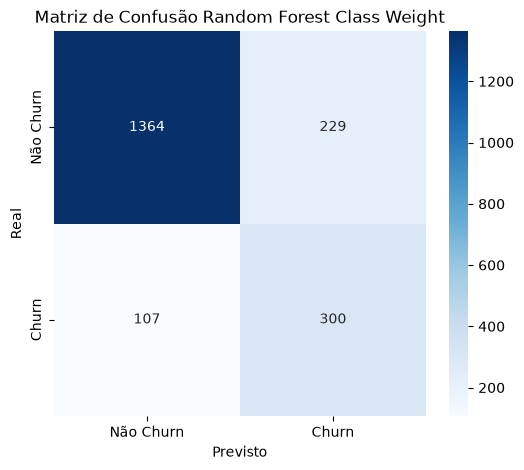

In [120]:
x_pred = pipeline_rf.predict(x_valid)
cm = confusion_matrix(y_valid, x_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Não Churn', 'Churn'],
            yticklabels=['Não Churn', 'Churn'])
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title('Matriz de Confusão Random Forest Class Weight')
plt.show()
#Plotando a matriz de confusão

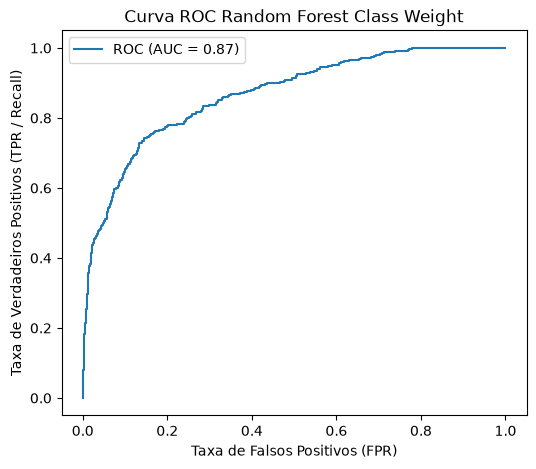

0.8669995110673077


In [121]:
x_proba = pipeline_rf.predict_proba(x_valid)[:, 1]

fpr, tpr, thresholds_roc = roc_curve(y_valid, x_proba)
auc_score = roc_auc_score(y_valid, x_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ROC (AUC = {auc_score:.2f})')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR / Recall)')
plt.title('Curva ROC Random Forest Class Weight')
plt.legend()
plt.show()

print(auc_score)
#Traçando a curva AUC-ROC

In [122]:
probabilities_valid = pipeline_rf.predict_proba(x_valid)
probabilities_one_valid = probabilities_valid[:,1]
# Encontrando as probabilidades da classe 1

In [123]:
print(probabilities_one_valid[:5])

[0.62145278 0.7921873  0.25839803 0.04323575 0.43074852]


In [124]:
for threshold in np.arange(0, 0.4, 0.02):
    predicted_valid = probabilities_one_valid > threshold 
    precision = precision_score(y_valid, predicted_valid)
    recall = recall_score(y_valid, predicted_valid)
    f1 = f1_score(y_valid, predicted_valid)
    print(
        'Limiar = {:.2f} | Precisão = {:.3f}, Sensibilidade = {:.3f}, F1_score = {:.3f}'.format(
            threshold, precision, recall, f1
        )
    )
# Percorrendo os valores limiares para encontrar o melhor F1

Limiar = 0.00 | Precisão = 0.203, Sensibilidade = 1.000, F1_score = 0.338
Limiar = 0.02 | Precisão = 0.204, Sensibilidade = 1.000, F1_score = 0.339
Limiar = 0.04 | Precisão = 0.207, Sensibilidade = 1.000, F1_score = 0.343
Limiar = 0.06 | Precisão = 0.214, Sensibilidade = 1.000, F1_score = 0.353
Limiar = 0.08 | Precisão = 0.223, Sensibilidade = 1.000, F1_score = 0.365
Limiar = 0.10 | Precisão = 0.233, Sensibilidade = 1.000, F1_score = 0.377
Limiar = 0.12 | Precisão = 0.245, Sensibilidade = 1.000, F1_score = 0.393
Limiar = 0.14 | Precisão = 0.256, Sensibilidade = 0.988, F1_score = 0.406
Limiar = 0.16 | Precisão = 0.267, Sensibilidade = 0.973, F1_score = 0.419
Limiar = 0.18 | Precisão = 0.278, Sensibilidade = 0.966, F1_score = 0.431
Limiar = 0.20 | Precisão = 0.288, Sensibilidade = 0.951, F1_score = 0.442
Limiar = 0.22 | Precisão = 0.302, Sensibilidade = 0.939, F1_score = 0.457
Limiar = 0.24 | Precisão = 0.315, Sensibilidade = 0.926, F1_score = 0.471
Limiar = 0.26 | Precisão = 0.329, Sens

## 8. Random Forest - Upsampling

In [125]:
pipeline_rf_up = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=5,
        random_state=12345
    ))
])

pipeline_rf_up.fit(x_train_upsampled, y_train_upsampled)
#Executando um pipeline para fazer o pré processamento das colunas e rodar o modelo, ensinei o modelo utilizando os treinos já com upsample

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['CreditScore','Geography','Gender',...,'HasCrCard','IsActiveMember', 'EstimatedSalary']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

In [126]:
x_pred = pipeline_rf_up.predict(x_valid)
print(classification_report(y_valid, x_pred))
print(f1_score(y_valid, x_pred))
#Verificando F1 

              precision    recall  f1-score   support

           0       0.91      0.90      0.90      1593
           1       0.63      0.63      0.63       407

    accuracy                           0.85      2000
   macro avg       0.77      0.77      0.77      2000
weighted avg       0.85      0.85      0.85      2000

0.63003663003663


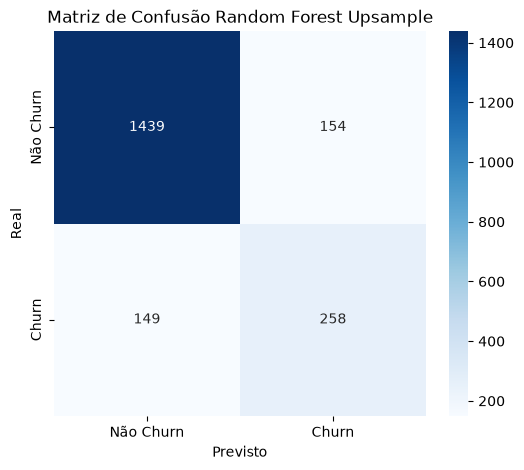

In [127]:
x_pred = pipeline_rf_up.predict(x_valid)
cm = confusion_matrix(y_valid, x_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Não Churn', 'Churn'],
            yticklabels=['Não Churn', 'Churn'])
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title('Matriz de Confusão Random Forest Upsample')
plt.show()
#Plotando a matriz de confusão

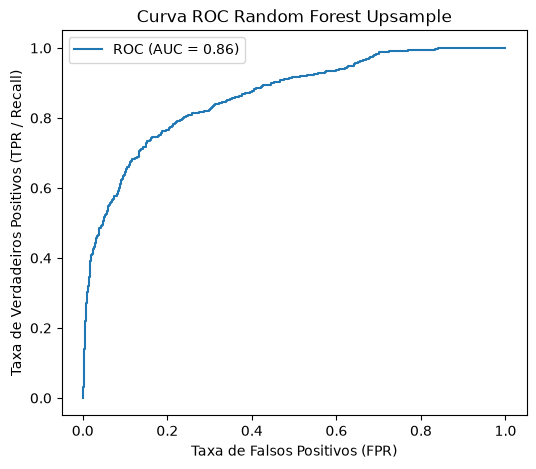

0.8621826757419978


In [128]:

x_proba = pipeline_rf_up.predict_proba(x_valid)[:, 1]

fpr, tpr, thresholds_roc = roc_curve(y_valid, x_proba)
auc_score = roc_auc_score(y_valid, x_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ROC (AUC = {auc_score:.2f})')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR / Recall)')
plt.title('Curva ROC Random Forest Upsample')
plt.legend()
plt.show()

print(auc_score)
#Traçando a curva AUC-ROC


In [129]:
probabilities_valid = pipeline_rf_up.predict_proba(x_valid)
probabilities_one_valid = probabilities_valid[:,1]
# Encontrando as probabilidades da classe 1

In [130]:
print(probabilities_one_valid[:5])

[0.43797575 0.80924238 0.17514495 0.06160902 0.38481848]


In [131]:
for threshold in np.arange(0, 0.4, 0.02):
    predicted_valid = probabilities_one_valid > threshold 
    precision = precision_score(y_valid, predicted_valid)
    recall = recall_score(y_valid, predicted_valid)
    f1 = f1_score(y_valid, predicted_valid)
    print(
        'Limiar = {:.2f} | Precisão = {:.3f}, Sensibilidade = {:.3f}, F1_score = {:.3f}'.format(
            threshold, precision, recall, f1
        )
    )
# Percorrendo os valores limiares para encontrar o melhor F1

Limiar = 0.00 | Precisão = 0.203, Sensibilidade = 1.000, F1_score = 0.338
Limiar = 0.02 | Precisão = 0.206, Sensibilidade = 1.000, F1_score = 0.342
Limiar = 0.04 | Precisão = 0.215, Sensibilidade = 1.000, F1_score = 0.353
Limiar = 0.06 | Precisão = 0.230, Sensibilidade = 1.000, F1_score = 0.373
Limiar = 0.08 | Precisão = 0.243, Sensibilidade = 0.995, F1_score = 0.390
Limiar = 0.10 | Precisão = 0.258, Sensibilidade = 0.990, F1_score = 0.409
Limiar = 0.12 | Precisão = 0.268, Sensibilidade = 0.971, F1_score = 0.420
Limiar = 0.14 | Precisão = 0.278, Sensibilidade = 0.948, F1_score = 0.430
Limiar = 0.16 | Precisão = 0.292, Sensibilidade = 0.931, F1_score = 0.445
Limiar = 0.18 | Precisão = 0.311, Sensibilidade = 0.919, F1_score = 0.464
Limiar = 0.20 | Precisão = 0.328, Sensibilidade = 0.912, F1_score = 0.482
Limiar = 0.22 | Precisão = 0.343, Sensibilidade = 0.894, F1_score = 0.496
Limiar = 0.24 | Precisão = 0.359, Sensibilidade = 0.875, F1_score = 0.509
Limiar = 0.26 | Precisão = 0.374, Sens

Analisando os valores obtidos com a random forest utilizando o upsample, eles estão bem próximos dos encontrados utilizando o class_weight, tanto precisão, recall, f1 e a curva AUC-ROC, com isso considero ele também um modelo apto ao teste final.

Para realizar o teste final considerei utilizar o random forest utilizando o class_weight='balanced', pois ele já mostrou ter um bom resultado e com ele não alteramos a estrutura do nosso dataframe, isso em comparação com o upsample no qual foi necessário multiplicarmos as linhas com a classe mais baixa.

## 9. Conjunto de Teste

In [132]:
x_pred_test = pipeline_rf.predict(x_test)

print(classification_report(y_test, x_pred_test))
print(f1_score(y_test, x_pred_test))
#Verificando F1 do conjunto de teste

              precision    recall  f1-score   support

           0       0.92      0.87      0.89      1593
           1       0.58      0.69      0.63       407

    accuracy                           0.84      2000
   macro avg       0.75      0.78      0.76      2000
weighted avg       0.85      0.84      0.84      2000

0.6313416009019166


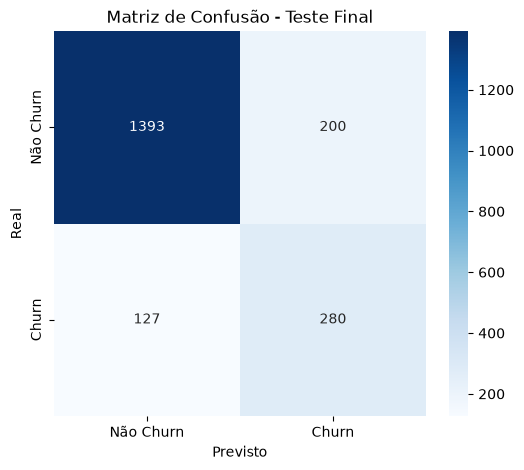

In [133]:
cm = confusion_matrix(y_test, x_pred_test)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Não Churn', 'Churn'],
            yticklabels=['Não Churn', 'Churn'])
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title('Matriz de Confusão - Teste Final')
plt.show()
#Plotando a matriz de confusão do conjunto de teste

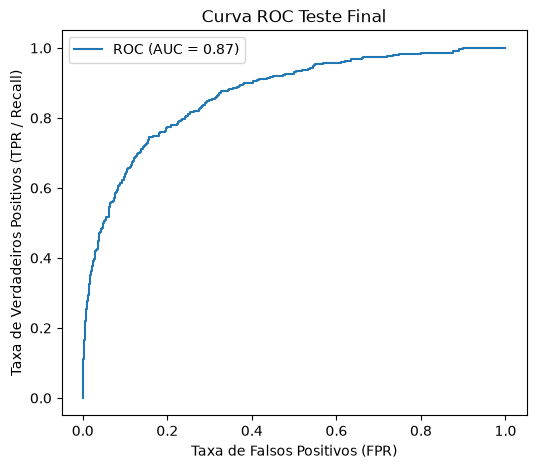

0.8672200706099011


In [134]:
x_proba_test = pipeline_rf.predict_proba(x_test)[:, 1]

fpr, tpr, thresholds_roc = roc_curve(y_test, x_proba_test)
auc_score = roc_auc_score(y_test, x_proba_test)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ROC (AUC = {auc_score:.2f})')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR / Recall)')
plt.title('Curva ROC Teste Final')
plt.legend()
plt.show()

print(auc_score)
#Traçando a curva AUC-ROC

Após rodarmos o conjunto de teste utilizando o modelo de random forest com o class_weight='balanced', obtivemos valores bem próximos dos obtidos no nosso conjunto de validação, o que demonstra que o modelo está lidando bem com novos dados e assim validando o funcionamento do mesmo.

## 10. Prova Real

In [135]:
score_forest_test = pipeline_rf.score(x_test, y_test)
print(f"Acurácia do modelo no conjunto de teste: {score_forest_test}")

Acurácia do modelo no conjunto de teste: 0.8365


In [136]:
print(y_test.value_counts(normalize=True))

Exited
0    0.7965
1    0.2035
Name: proportion, dtype: float64


Levantei a proporção de clientes que cancelaram (1) e que não cancelaram (0) no target test e verifiquei a proporção de aproximadamente 79% que não cancelaram e 20% que cancelaram, isso mostra que o modelo realmente está aprendendo padrões de dados úteis e não somente "chutando" a classe mais presente, levando em conta que o nosso teste apresentou um valor de acurácia de aproximandamente 85%, ou seja 6 pontos percentuais acima da maior classe.